<div dir="rtl" style="text-align:right"><h1>שיעור 3, חלק 1: מנוירון לייצוג – איך מחשב לומד – שלב B: רשת שלומדת</h1>
<p><b>המחברת הזו היא לשלב B («רשת שלומדת») בשיעור באתר הקורס – ורק לו.</b> את ההסבר קוראים באתר; כאן מריצים ומשנים.</p>
<p>מריצים תא אחרי תא בלחיצה על ▶, מלמעלה למטה. מעבד רגיל (<code>CPU</code>) מספיק; אין צורך ב-<code>GPU</code>, במפתח <code>API</code> או במנוי. <b>אין חובת הגשת מחברת.</b></p></div>

In [1]:
# Setup. Everything below is preinstalled on Google Colab.
import warnings

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)
print("scikit-learn", sklearn.__version__, "- setup done")

scikit-learn 1.9.1 - setup done


<div dir="rtl" style="text-align:right"><h2>2 | רשת קטנה לומדת מדוגמאות</h2>
<p><b>רשת נוירונים</b> היא שכבות של נוירונים כאלה: הפלט של שכבה אחת הוא הקלט של הבאה. <b>אימון</b> (כמו בשיעור 2) פירושו לשנות את המשקלים צעד אחרי צעד, כך שהשגיאה על דוגמאות האימון קטנה. כל המספרים שהאימון קובע – המשקלים וההטיות – נקראים <b>פרמטרים</b>.</p>
<p>הנתונים <b>בדויים</b>: כלל פשוט עם מעט רעש קובע אם היה צריך עוד מגש. נשתמש ב-<code>MLPClassifier</code> של <code>scikit-learn</code>: רשת עם שכבה נסתרת אחת.</p>
<blockquote>① נחשו: אחרי צעד אימון אחד, הרשת כבר תצדק ברוב הדוגמאות? ואחרי 300?</blockquote></div>

In [2]:
rng = np.random.default_rng(3)
orders = rng.integers(0, 21, 160).astype(float)
leftover = rng.integers(0, 11, 160).astype(float)
needed = (orders - 1.5 * leftover + rng.normal(0, 1.5, 160) > 5).astype(int)  # made-up rule + noise
X = np.column_stack([orders / 20, leftover / 10])  # scaled to 0..1
X_train, y_train, X_test, y_test = X[:120], needed[:120], X[120:], needed[120:]


def train(hidden=8, learning_rate=0.005, steps=300, report=True):
    """Train step by step (one pass over the 120 examples per step)."""
    net = MLPClassifier(hidden_layer_sizes=(hidden,), learning_rate_init=learning_rate, max_iter=1, warm_start=True, random_state=0)
    losses, snapshots, train_acc = [], {}, {}
    for step in range(1, steps + 1):
        net.fit(X_train, y_train)
        losses.append(net.loss_)
        if step in (1, steps):
            snapshots[step] = (net.coefs_[0].copy(), net.intercepts_[0].copy(), net.coefs_[1].copy(), net.intercepts_[1].copy())
            train_acc[step] = net.score(X_train, y_train)
        if report and step in (1, 50, 100, 200, 300):
            print(f"step {step:3}: loss {net.loss_:.3f}   accuracy on training examples {net.score(X_train, y_train):.0%}")
    return net, losses, snapshots, train_acc


net, losses, snapshots, train_acc = train()  # the baseline: 8 hidden neurons, learning rate 0.005
print(f"loss after 1 step: {losses[0]:.3f}   after 300 steps: {losses[-1]:.3f}")
print(f"accuracy on the training examples: {train_acc[1]:.0%} after 1 step, {train_acc[300]:.0%} after 300")
print(f"accuracy on 40 examples the network did not train on: {net.score(X_test, y_test):.0%}")

step   1: loss 0.647   accuracy on training examples 66%
step  50: loss 0.472   accuracy on training examples 82%


step 100: loss 0.342   accuracy on training examples 87%


step 200: loss 0.190   accuracy on training examples 91%


step 300: loss 0.151   accuracy on training examples 92%
loss after 1 step: 0.647   after 300 steps: 0.151
accuracy on the training examples: 66% after 1 step, 92% after 300
accuracy on 40 examples the network did not train on: 90%


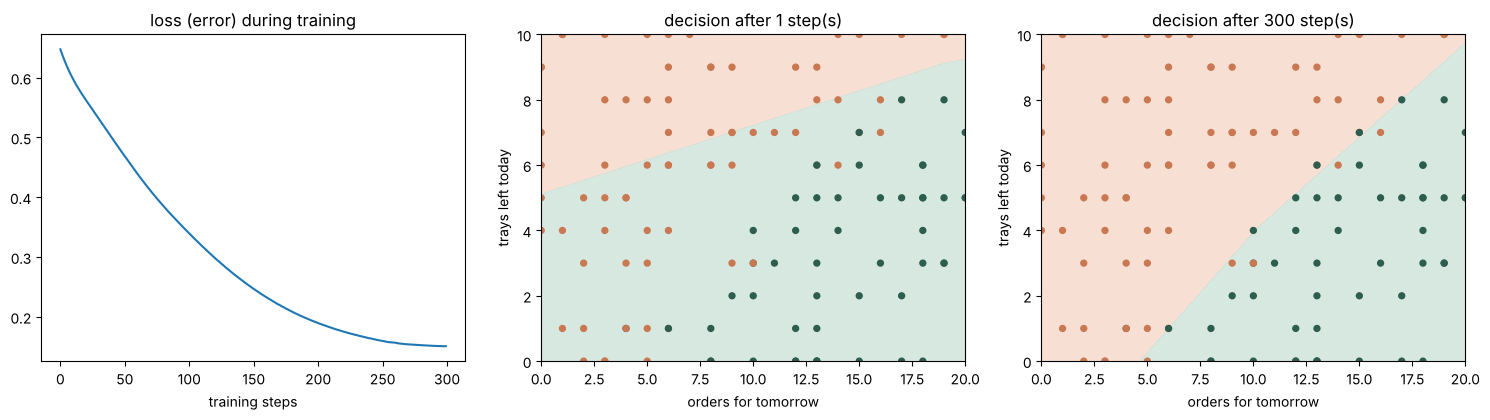

In [3]:
def predict_with(snapshot, points):
    w1, b1, w2, b2 = snapshot
    hidden = np.maximum(0, points @ w1 + b1)  # ReLU
    return (1 / (1 + np.exp(-(hidden @ w2 + b2)))).ravel()


grid_x, grid_y = np.meshgrid(np.linspace(0, 1, 120), np.linspace(0, 1, 120))
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(losses)
axes[0].set_title("loss (error) during training")
axes[0].set_xlabel("training steps")
for ax, step in zip(axes[1:], (1, 300)):
    p = predict_with(snapshots[step], grid).reshape(grid_x.shape)
    ax.contourf(grid_x * 20, grid_y * 10, p, levels=[0, 0.5, 1], colors=["#f5d9c8", "#cee3da"], alpha=0.8)
    ax.scatter(X_train[:, 0] * 20, X_train[:, 1] * 10, c=np.where(y_train, "#2d5d4f", "#c97852"), s=18)
    ax.set_title(f"decision after {step} step(s)")
    ax.set_xlabel("orders for tomorrow")
    ax.set_ylabel("trays left today")
plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align:right"><p>משמאל: השגיאה יורדת לאורך האימון. באמצע ומימין: האזור הירוק הוא «לאפות עוד מגש». אחרי צעד אחד הרשת עוד כמעט לא מבחינה בין המקרים; אחרי 300 צעדים הקו מפריד את רוב הנקודות (לא את כולן – יש רעש בנתונים). אף אחד לא כתב את הכלל ביד – האימון כיוונן את המשקלים.</p>
<h3>2א | משנים דבר אחד: קצב הלמידה וגודל הרשת</h3>
<p><b>קצב הלמידה</b> קובע כמה גדול כל צעד אימון. <b>גודל השכבה הנסתרת</b> קובע כמה נוירונים יש בה.</p>
<blockquote>① נחשו: קצב למידה קטן פי 10 – השגיאה אחרי 300 צעדים תהיה גבוהה יותר או נמוכה יותר? ומה עם 2 נוירונים במקום 8?</blockquote>
<p>③ בתא הבא כל שורה משנה <b>דבר אחד</b> לעומת שורת הבסיס. הוסיפו שורה משלכם והריצו שוב.</p></div>

In [4]:
print(f"{'hidden':>6} {'learning rate':>13} {'loss after 300':>14} {'train acc':>9} {'test acc':>8}")
for hidden, lr in [(8, 0.005), (8, 0.0005), (8, 0.05), (2, 0.005), (32, 0.005)]:  # <- ③ add your own row
    n, l, _, acc = train(hidden=hidden, learning_rate=lr, report=False)
    print(f"{hidden:6} {lr:13} {l[-1]:14.3f} {acc[300]:9.0%} {n.score(X_test, y_test):8.0%}")

hidden learning rate loss after 300 train acc test acc


     8         0.005          0.151       92%      90%


     8        0.0005          0.531       78%      85%


     8          0.05          0.327       86%      88%


     2         0.005          0.323       86%      85%


    32         0.005          0.162       91%      92%


<div dir="rtl" style="text-align:right"><p>④ שימו לב: קצב קטן מדי – הרשת כמעט לא מתקדמת ב-300 צעדים. גדול יותר – מתקדמת מהר יותר (ולא תמיד טוב יותר). שנו בכל שורה רק דבר אחד, כמו בשיעור 2.</p>
<h3>2ב | כמה פרמטרים יש ברשת?</h3>
<p>כל חיבור בין נוירונים הוא משקל, ולכל נוירון יש הטיה. עם 2 קלטים, 8 נוירונים נסתרים ופלט אחד: 2×8 משקלים + 8 הטיות + 8×1 משקלים + הטיה אחת.</p>
<blockquote>① נחשו את המספר לפני שמריצים.</blockquote></div>

In [5]:
def count_parameters(net):
    return sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_)


print("baseline network (8 hidden):", count_parameters(net), "parameters")  # 2*8 + 8 + 8*1 + 1
for hidden in (2, 32):  # <- ③ try another size
    n, _, _, _ = train(hidden=hidden, report=False)
    print(f"{hidden} hidden:", count_parameters(n), "parameters")
print("For comparison, the small language model in part 2 has about 0.49 billion (its notebook counts them).")

baseline network (8 hidden): 33 parameters


2 hidden: 9 parameters


32 hidden: 129 parameters
For comparison, the small language model in part 2 has about 0.49 billion (its notebook counts them).


<div dir="rtl" style="text-align:right"><p><b>סיימתם את המחברת של שלב B.</b> חזרו ללשונית של אתר הקורס וענו שם על שאלות השלב.</p></div>